🏃‍♂️ Health & Fitness Trends
Company: VitalityApp Role: Health Data Scientist

🏢 Scenario
VitalityApp tracks daily user movement and body metrics. The marketing team wants to segment users into “Active” and “Inactive” categories to send personalized workout notifications and improve engagement.


In [ ]:
import pandas as pd
from google.colab import files
uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))
display(df)

Saving health_fitness_dataset.csv to health_fitness_dataset (1).csv


,Person_ID,Age,Weight_kg,Height_cm,Daily_Steps
0,3001,55,96,167,9777
1,3002,40,55,188,13914
2,3003,56,50,188,5935
3,3004,55,78,179,14567
4,3005,60,96,173,12458
5,3006,31,71,169,3162
6,3007,21,66,180,11603
7,3008,50,69,189,8938
8,3009,19,81,188,14371
9,3010,52,92,186,7067


1️⃣ Daily Activity Analysis Calculate the average daily steps across all users. This provides a baseline activity benchmark.

In [ ]:
display(df)

total = df["Daily_Steps"].sum()
count = df["Daily_Steps"].count()

print("Total Steps:", total)
print("Total Users:", count)
print("Average Steps:", total / count)


,Person_ID,Age,Weight_kg,Height_cm,Daily_Steps
0,3001,55,96,167,9777
1,3002,40,55,188,13914
2,3003,56,50,188,5935
3,3004,55,78,179,14567
4,3005,60,96,173,12458
5,3006,31,71,169,3162
6,3007,21,66,180,11603
7,3008,50,69,189,8938
8,3009,19,81,188,14371
9,3010,52,92,186,7067


Total Steps: 201616
Total Users: 20
Average Steps: 10080.8


2️⃣ Identify Power Users
Filter users who walk:
Steps > 10,000 per day
These users represent highly active individuals.

In [ ]:
power_users=df[df["Daily_Steps"]>10000]
print("Power Users(Daily Steps>10,000):")
print(power_users.to_string(index=False))
print(f"\nTotal Power Users Identified: {len(power_users)}")

Power Users(Daily Steps>10,000):
 Person_ID  Age  Weight_kg  Height_cm  Daily_Steps
      3002   40         55        188        13914
      3004   55         78        179        14567
      3005   60         96        173        12458
      3007   21         66        180        11603
      3009   19         81        188        14371
      3011   38         86        156        12777
      3013   55         71        190        10973
      3017   38         64        179        14304
      3018   55         79        183        14312
      3019   48         88        177        10681

Total Power Users Identified: 10


3️⃣ Step Distribution
Create a Histogram of daily steps.

Include:

Title
Axis labels
Grid (optional)
Analyze how steps are distributed among users.

,Person_ID,Age,Weight_kg,Height_cm,Daily_Steps
0,3001,55,96,167,9777
1,3002,40,55,188,13914
2,3003,56,50,188,5935
3,3004,55,78,179,14567
4,3005,60,96,173,12458
5,3006,31,71,169,3162
6,3007,21,66,180,11603
7,3008,50,69,189,8938
8,3009,19,81,188,14371
9,3010,52,92,186,7067


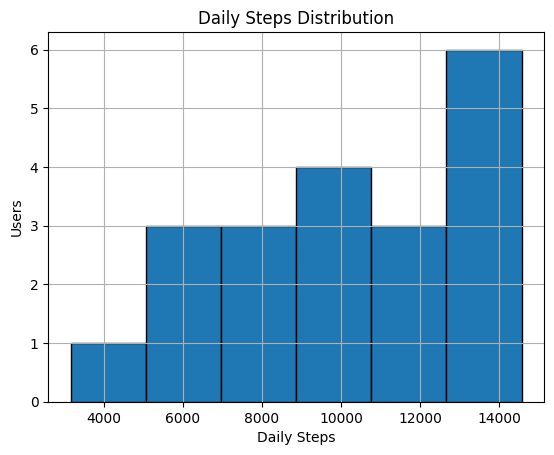

In [ ]:
import matplotlib.pyplot as plt
display(df)
plt.hist(df["Daily_Steps"], bins=6, edgecolor="black")
plt.title("Daily Steps Distribution")
plt.xlabel("Daily Steps")
plt.ylabel("Users")
plt.grid()
plt.show()

4️⃣ Body Metrics Relationship
Create a Scatter Plot showing:
Weight vs. Height
Include:

Clear chart title
Axis labels
Observe any visible trends or clusters.

,Person_ID,Age,Weight_kg,Height_cm,Daily_Steps
0,3001,55,96,167,9777
1,3002,40,55,188,13914
2,3003,56,50,188,5935
3,3004,55,78,179,14567
4,3005,60,96,173,12458
5,3006,31,71,169,3162
6,3007,21,66,180,11603
7,3008,50,69,189,8938
8,3009,19,81,188,14371
9,3010,52,92,186,7067


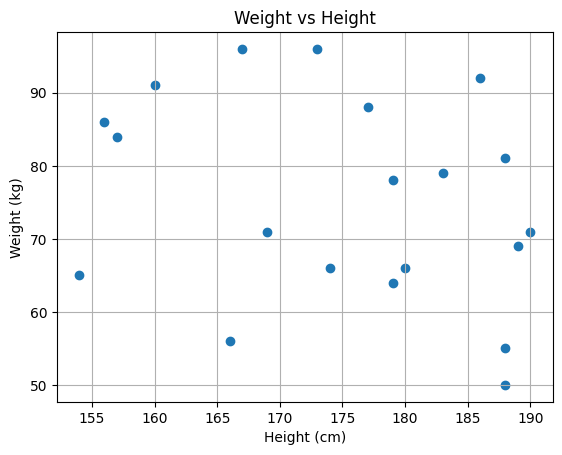

In [ ]:
display(df)
plt.scatter(df["Height_cm"], df["Weight_kg"])
plt.title("Weight vs Height")
plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
plt.grid()
plt.show()

5️⃣ User Segmentation
Create a new column called Active_User where:
Active_User = True  if Steps ≥ 8000  
Active_User = False if Steps < 8000
This will segment users for marketing campaigns.

In [ ]:
df["Active_User"] = df["Daily_Steps"] >= 8000

display(df)
print(df["Active_User"].value_counts())

,Person_ID,Age,Weight_kg,Height_cm,Daily_Steps,Active_User
0,3001,55,96,167,9777,True
1,3002,40,55,188,13914,True
2,3003,56,50,188,5935,False
3,3004,55,78,179,14567,True
4,3005,60,96,173,12458,True
5,3006,31,71,169,3162,False
6,3007,21,66,180,11603,True
7,3008,50,69,189,8938,True
8,3009,19,81,188,14371,True
9,3010,52,92,186,7067,False


Active_User
True     14
False     6
Name: count, dtype: int64


6️⃣ Activity Comparison
Count how many users are:

✅ Active
❌ Inactive
Summarize the proportion of each segment.

,Person_ID,Age,Weight_kg,Height_cm,Daily_Steps,Active_User
0,3001,55,96,167,9777,True
1,3002,40,55,188,13914,True
2,3003,56,50,188,5935,False
3,3004,55,78,179,14567,True
4,3005,60,96,173,12458,True
5,3006,31,71,169,3162,False
6,3007,21,66,180,11603,True
7,3008,50,69,189,8938,True
8,3009,19,81,188,14371,True
9,3010,52,92,186,7067,False


Active_User
True     14
False     6
Name: count, dtype: int64
Active_User
True     70.0
False    30.0
Name: count, dtype: float64


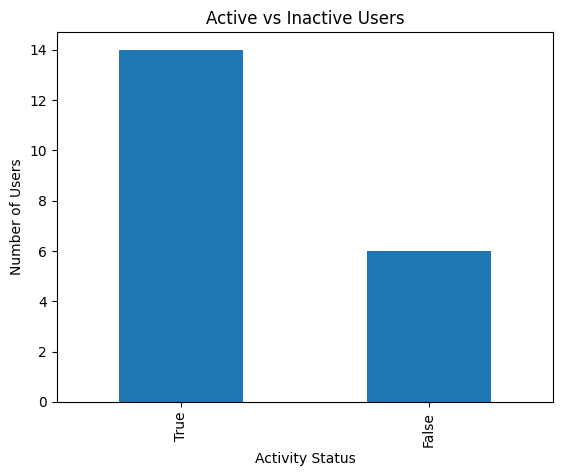

In [ ]:
display(df)
counts = df["Active_User"].value_counts()
print(counts)
print((counts / len(df) * 100).round(1))
counts.plot(kind="bar", title="Active vs Inactive Users")
plt.xlabel("Activity Status")
plt.ylabel("Number of Users")
plt.show()